In [1]:
!pip install -q timm torchmetrics thop grad-cam kaggle torchinfo snntorch

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Imports and reproducibility

In [2]:
import os
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)
from thop import profile
from torchinfo import summary

sns.set_style("darkgrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device)
print("Mixed precision:", USE_AMP)
print("timm version:", timm.__version__)

Device: cuda
Mixed precision: True
timm version: 1.0.30


In [3]:
# Google Colab: upload kaggle.json when prompted.
try:
    from google.colab import files
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Please upload a file named kaggle.json")
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    with open(kaggle_dir / "kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])
    os.chmod(kaggle_dir / "kaggle.json", 0o600)
    print("Kaggle credentials configured.")
except ImportError:
    kaggle_path = Path.home() / ".kaggle" / "kaggle.json"
    if not kaggle_path.exists():
        raise FileNotFoundError(
            f"Place your Kaggle API token at {kaggle_path} before continuing."
        )
    os.chmod(kaggle_path, 0o600)
    print("Using existing Kaggle credentials:", kaggle_path)

Saving kaggle.json to kaggle.json
Kaggle credentials configured.


## 4. Download the same dataset

In [4]:
from kaggle.api.kaggle_api_extended import KaggleApi

DATA_DIR = Path("brain_tumor_mri_data")
DATASET = "sartajbhuvaji/brain-tumor-classification-mri"

if not DATA_DIR.exists() or not any(DATA_DIR.iterdir()):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files(DATASET, path=str(DATA_DIR), unzip=True)

print("Dataset directory:", DATA_DIR.resolve())
print("Top-level entries:", [p.name for p in DATA_DIR.iterdir()][:20])

Dataset URL: https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri
Dataset directory: /content/brain_tumor_mri_data
Top-level entries: ['Testing', 'Training']


In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

# Locate the directory whose immediate subfolders are the image classes.
class_root_candidates = []
for root, dirs, files in os.walk(DATA_DIR):
    root_path = Path(root)
    valid_class_dirs = []
    for dirname in dirs:
        child = root_path / dirname
        image_count = sum(1 for p in child.iterdir()
                          if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if image_count > 0:
            valid_class_dirs.append((child, image_count))
    if len(valid_class_dirs) >= 2:
        class_root_candidates.append((root_path, sum(n for _, n in valid_class_dirs), valid_class_dirs))

if not class_root_candidates:
    raise RuntimeError(
        "Could not identify class folders. Inspect the extracted dataset structure and set DATA_ROOT manually."
    )

# Prefer the candidate with the largest number of images in its immediate class folders.
DATA_ROOT, _, class_dirs_info = max(class_root_candidates, key=lambda x: x[1])
class_names = sorted([p.name for p, _ in class_dirs_info])
label_map = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in label_map.items()}

records = []
for class_name in class_names:
    class_dir = DATA_ROOT / class_name
    for image_path in sorted(class_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            records.append({
                "image_path": str(image_path),
                "label": label_map[class_name],
                "class_name": class_name
            })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError(f"No images found under {DATA_ROOT}")

num_classes = len(class_names)
print("Selected data root:", DATA_ROOT)
print("Classes:", label_map)
print("Total images:", len(df))
print("Class distribution:\n", df["class_name"].value_counts())
display(df.head())

Selected data root: brain_tumor_mri_data/Training
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Total images: 2870
Class distribution:
 class_name
pituitary_tumor     827
glioma_tumor        826
meningioma_tumor    822
no_tumor            395
Name: count, dtype: int64


,image_path,label,class_name
0,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
1,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
2,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
3,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
4,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor


## 6. Train / validation / test split

In [6]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_df, test_size=0.20, stratify=train_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

Train: 1836 | Validation: 460 | Test: 574


## 7. Dataset, transforms, and dataloaders

In [7]:
class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(int(row["label"]), dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 2  # Memory-conscious for the added SNN/attention modules
NUM_WORKERS = 2
pin_memory = device.type == "cuda"

train_loader = DataLoader(BrainTumorDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(BrainTumorDataset(val_df, val_test_transform),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(BrainTumorDataset(test_df, val_test_transform),
                         batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 115 29 36


In [8]:
import snntorch as snn
from snntorch import surrogate

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden=max(channels//reduction,1)
        self.avg_pool=nn.AdaptiveAvgPool2d(1)
        self.max_pool=nn.AdaptiveMaxPool2d(1)
        self.shared_mlp=nn.Sequential(nn.Conv2d(channels,hidden,1,bias=False),nn.ReLU(inplace=True),nn.Conv2d(hidden,channels,1,bias=False))
        self.sigmoid=nn.Sigmoid()
    def forward(self,x):
        return x*self.sigmoid(self.shared_mlp(self.avg_pool(x))+self.shared_mlp(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self,kernel_size=7):
        super().__init__(); self.conv=nn.Conv2d(2,1,kernel_size,padding=kernel_size//2,bias=False); self.sigmoid=nn.Sigmoid()
    def forward(self,x):
        avg=torch.mean(x,dim=1,keepdim=True); mx=torch.max(x,dim=1,keepdim=True)[0]
        return x*self.sigmoid(self.conv(torch.cat([avg,mx],dim=1)))

class CBAM(nn.Module):
    def __init__(self,channels):
        super().__init__(); self.channel_attention=ChannelAttention(channels); self.spatial_attention=SpatialAttention(7)
    def forward(self,x): return self.spatial_attention(self.channel_attention(x))

class ResidualSNNBlock(nn.Module):
    """Single-step residual spiking block; membrane state is reset per forward call."""
    def __init__(self,channels,beta=0.95):
        super().__init__()
        self.conv1=nn.Conv2d(channels,channels,3,padding=1,bias=False); self.bn1=nn.BatchNorm2d(channels)
        self.lif1=snn.Leaky(beta=beta,spike_grad=surrogate.fast_sigmoid())
        self.conv2=nn.Conv2d(channels,channels,3,padding=1,bias=False); self.bn2=nn.BatchNorm2d(channels)
        self.lif2=snn.Leaky(beta=beta,spike_grad=surrogate.fast_sigmoid())
    def forward(self,x):
        identity=x; mem1=self.lif1.init_leaky(); mem2=self.lif2.init_leaky()
        y,mem1=self.lif1(self.bn1(self.conv1(x)),mem1)
        y,mem2=self.lif2(self.bn2(self.conv2(y)),mem2)
        return y+identity

class ConvNeXtCBAMSNNViT(nn.Module):
    """ConvNeXt-Tiny [3,1] -> CBAM -> SNN -> compact ViT encoder -> classifier."""
    def __init__(self,num_classes,pretrained=True,dropout=0.4,snn_beta=0.95):
        super().__init__()
        base=timm.create_model('convnext_tiny',pretrained=pretrained,num_classes=0)
        self.stem=base.stem; stage1=base.stages[0]; stage2=base.stages[1]
        stage2.blocks=nn.Sequential(*list(stage2.blocks.children())[:1]); self.stages=nn.Sequential(stage1,stage2); del base
        self.feature_channels=192; self.cbam=CBAM(192)
        self.snn1=ResidualSNNBlock(192,snn_beta); self.snn2=ResidualSNNBlock(192,snn_beta)
        # Reduce 56x56 to 14x14 tokens (196 tokens) before self-attention.
        self.patch_embed=nn.Conv2d(192,192,kernel_size=4,stride=4)
        self.cls_token=nn.Parameter(torch.zeros(1,1,192))
        self.pos_embed=nn.Parameter(torch.zeros(1,197,192))
        encoder_layer=nn.TransformerEncoderLayer(d_model=192,nhead=6,dim_feedforward=768,dropout=0.1,activation='gelu',batch_first=True,norm_first=True)
        self.vit_encoder=nn.TransformerEncoder(encoder_layer,num_layers=4,enable_nested_tensor=False)
        self.norm=nn.LayerNorm(192); self.dropout=nn.Dropout(dropout); self.classifier=nn.Linear(192,num_classes)
        nn.init.trunc_normal_(self.cls_token,std=0.02); nn.init.trunc_normal_(self.pos_embed,std=0.02)
    def forward_features(self,x): return self.stages(self.stem(x))
    def forward(self,x):
        x=self.forward_features(x); x=self.cbam(x); x=self.snn1(x); x=self.snn2(x)
        x=self.patch_embed(x).flatten(2).transpose(1,2)
        cls=self.cls_token.expand(x.size(0),-1,-1)
        x=torch.cat([cls,x],dim=1)+self.pos_embed
        x=self.vit_encoder(x)[:,0]
        return self.classifier(self.dropout(self.norm(x)))

model=ConvNeXtCBAMSNNViT(num_classes=num_classes,pretrained=True).to(device)
retained_block_counts=[len(stage.blocks) for stage in model.stages]
assert retained_block_counts==[3,1] and sum(retained_block_counts)==4
with torch.no_grad():
    dummy=torch.randn(1,3,448,448,device=device); feature_map=model.forward_features(dummy)
    attended_map=model.cbam(feature_map); logits=model(dummy)
print('Retained ConvNeXt blocks:',retained_block_counts)
print('Backbone feature map:',tuple(feature_map.shape),'| CBAM map:',tuple(attended_map.shape),'| logits:',tuple(logits.shape))
assert tuple(feature_map.shape[1:])==(192,56,56)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Retained stage block counts: [3, 1]
Total retained ConvNeXt blocks: 4
Feature map shape: (2, 192, 56, 56)
Logits shape: (2, 4)


## 9. Model summary and complexity

The model summary includes the four retained ConvNeXt blocks, CBAM, and classification head.

In [9]:
summary(
    model,
    input_size=(1, 3, 448, 448),
    col_names=["input_size", "output_size", "num_params", "kernel_size"],
    depth=4
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model.eval()
dummy_input = torch.randn(1, 3, 448, 448, device=device)
flops, thop_params = profile(model, inputs=(dummy_input,), verbose=False)
print(f"THOP FLOPs: {flops:,.0f} ({flops / 1e9:.4f} GFLOPs)")
print(f"THOP parameters: {thop_params:,.0f} ({thop_params / 1e6:.4f} M)")
model.train()

Trainable parameters: 624,100
Total parameters: 624,100
THOP FLOPs: 4,195,518,144 (4.1955 GFLOPs)
THOP parameters: 622,276 (0.6223 M)


TruncatedConvNeXt(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), gr

## 10. Loss, optimizer, and learning-rate schedule

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4, betas=(0.9, 0.999)
)

TOTAL_EPOCHS = 20
WARMUP_EPOCHS = 5
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=TOTAL_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BEST_MODEL_PATH = "best_convnext_4block_cbam_snn_vit_56x56.pth"
print("Checkpoint:", BEST_MODEL_PATH)

Checkpoint: best_convnext_truncated_56x56_4blocks.pth


## 11. Metric helpers

In [11]:
def specificity_sensitivity(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    specificity, sensitivity = [], []
    for i in range(n_classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specificity.append(tn / (tn + fp + 1e-8))
        sensitivity.append(tp / (tp + fn + 1e-8))
    return float(np.mean(specificity)), float(np.mean(sensitivity))


def calculate_metrics(y_true, y_pred, y_prob, n_classes):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    try:
        if n_classes == 2:
            metrics["auc"] = roc_auc_score(y_true, y_prob[:, 1])
        else:
            metrics["auc"] = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except ValueError:
        metrics["auc"] = float("nan")
    metrics["specificity"], metrics["sensitivity"] = specificity_sensitivity(
        y_true, y_pred, n_classes
    )
    return metrics

In [12]:
!pip install torchinfo thop torchview graphviz -q

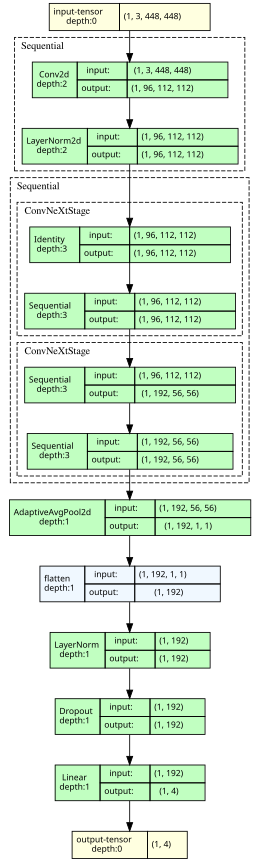

In [13]:
from torchview import draw_graph
from IPython.display import SVG, display

dummy_input = torch.randn(1, 3, 448, 448).to(device)

graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="ConvNeXtCBAMSNNViT",
    save_graph=True,              # IMPORTANT
    filename="ConvNeXtCBAMSNNViT_BlockDiagram",
    directory="."
)

# Display inline
svg = graph.visual_graph.pipe(format="svg")
display(SVG(svg))


## 12. Training and validation

In [14]:
history = {
    "loss": [], "val_loss": [],
    "accuracy": [], "val_accuracy": [],
    "precision": [], "val_precision": [],
    "recall": [], "val_recall": [],
    "f1": [], "val_f1": [],
    "auc": [], "val_auc": [],
    "mcc": [], "val_mcc": [],
    "specificity": [], "val_specificity": [],
    "sensitivity": [], "val_sensitivity": []
}

best_val_acc = -1.0
patience = 7
patience_counter = 0

for epoch in range(TOTAL_EPOCHS):
    # -------------------- TRAIN --------------------
    model.train()
    running_loss = 0.0
    train_true, train_pred, train_prob = [], [], []

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Train")
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        probs = torch.softmax(outputs.detach(), dim=1)
        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(outputs.detach().argmax(1).cpu().numpy())
        train_prob.extend(probs.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}", lr=f"{optimizer.param_groups[0]['lr']:.2e}")

    train_loss = running_loss / max(1, len(train_loader))
    train_metrics = calculate_metrics(
        np.asarray(train_true), np.asarray(train_pred), np.asarray(train_prob), num_classes
    )

    # -------------------- VALIDATION --------------------
    model.eval()
    val_running_loss = 0.0
    val_true, val_pred, val_prob = [], [], []
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Val"):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(outputs.argmax(1).cpu().numpy())
            val_prob.extend(probs.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))
    val_metrics = calculate_metrics(
        np.asarray(val_true), np.asarray(val_pred), np.asarray(val_prob), num_classes
    )

    # Step scheduler after the epoch.
    if epoch < WARMUP_EPOCHS:
        warmup_scheduler.step()
    else:
        cosine_scheduler.step()

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    for key in train_metrics:
        history[key].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])

    print(
        f"\nEpoch {epoch+1}: "
        f"train loss={train_loss:.4f}, acc={train_metrics['accuracy']:.4f}, "
        f"F1={train_metrics['f1']:.4f}, AUC={train_metrics['auc']:.4f} | "
        f"val loss={val_loss:.4f}, acc={val_metrics['accuracy']:.4f}, "
        f"F1={val_metrics['f1']:.4f}, AUC={val_metrics['auc']:.4f}"
    )
    print(
        f"Val precision={val_metrics['precision']:.4f}, recall={val_metrics['recall']:.4f}, "
        f"specificity={val_metrics['specificity']:.4f}, "
        f"sensitivity={val_metrics['sensitivity']:.4f}, MCC={val_metrics['mcc']:.4f}"
    )
    print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6e}")

    if val_metrics["accuracy"] > best_val_acc:
        best_val_acc = val_metrics["accuracy"]
        patience_counter = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "num_classes": num_classes,
            "class_to_idx": label_map,
            "best_val_accuracy": best_val_acc,
            "epoch": epoch + 1,
            "architecture": "ConvNeXt-Tiny stem + stages 0-1 (6 blocks), GAP, LayerNorm, Dropout, Linear"
        }, BEST_MODEL_PATH)
        print(f"Saved best checkpoint (val accuracy={best_val_acc:.4f})")
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

print(f"\nBest validation accuracy: {best_val_acc:.4f}")

Epoch 1/20 - Train:   0%|          | 0/115 [00:00<?, ?it/s]

Epoch 1/20 - Val:   0%|          | 0/29 [00:00<?, ?it/s]


Epoch 1: train loss=1.3166, acc=0.3693, F1=0.2784, AUC=0.6168 | val loss=1.2069, acc=0.4978, F1=0.3540, AUC=nan
Val precision=0.4001, recall=0.4323, specificity=0.8238, sensitivity=0.4323, MCC=0.3376
Learning rate: 8.400000e-05
Saved best checkpoint (val accuracy=0.4978)


Epoch 2/20 - Train:   0%|          | 0/115 [00:00<?, ?it/s]

Epoch 2/20 - Val:   0%|          | 0/29 [00:00<?, ?it/s]


Epoch 2: train loss=1.1214, acc=0.5387, F1=0.5032, AUC=nan | val loss=0.9748, acc=0.6239, F1=0.5868, AUC=nan
Val precision=0.7019, recall=0.5918, specificity=0.8691, sensitivity=0.5918, MCC=0.5138
Learning rate: 1.380000e-04
Saved best checkpoint (val accuracy=0.6239)


... (70 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cd8f2cbee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cd8f2cbee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 20/20 - Val:   0%|          | 0/29 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cd8f2cbee80>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7cd8f2cbee80>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorif w.is_alive():
:   File "/usr/lib/python3.13/multiprocessing/pro


Epoch 20: train loss=0.4636, acc=0.9526, F1=0.9508, AUC=nan | val loss=0.4861, acc=0.9283, F1=0.9272, AUC=nan
Val precision=0.9295, recall=0.9251, specificity=0.9754, sensitivity=0.9251, MCC=0.9021
Learning rate: 1.000000e-06

Best validation accuracy: 0.9413


## 13. Plot training curves

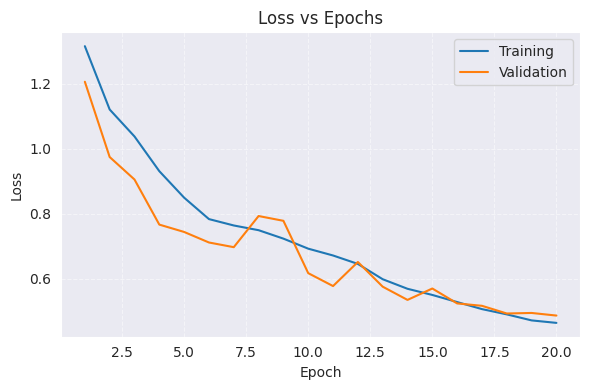

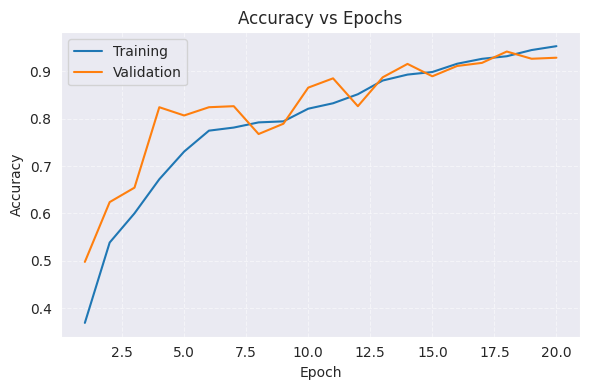

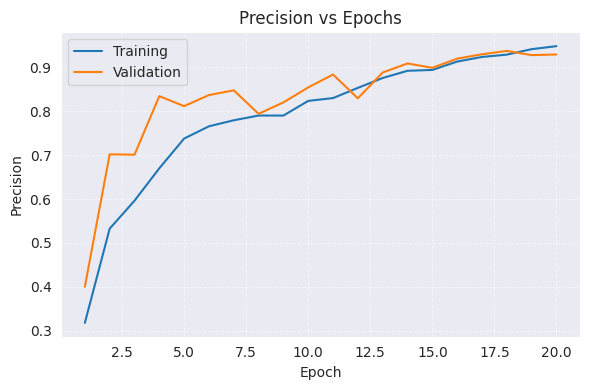

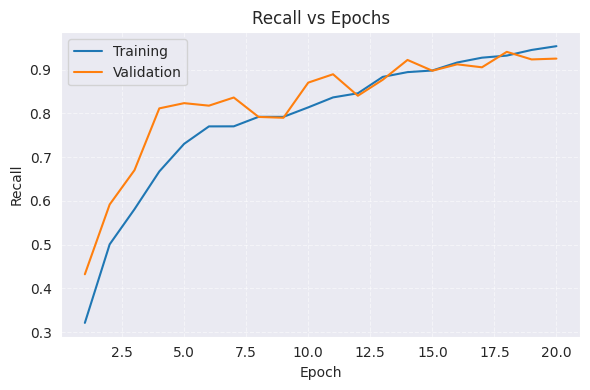

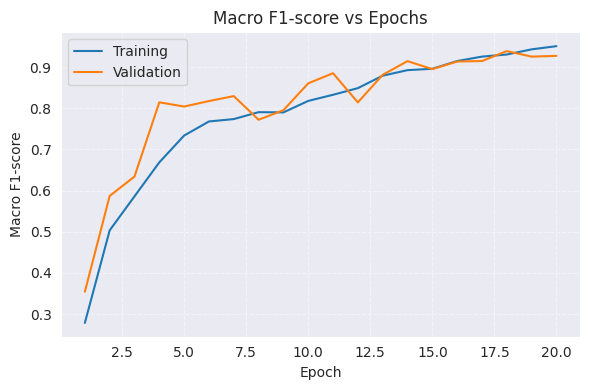

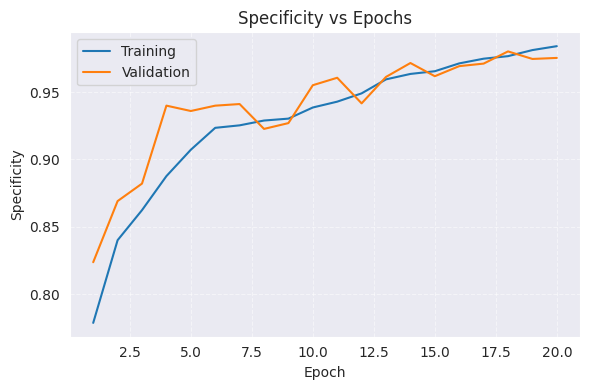

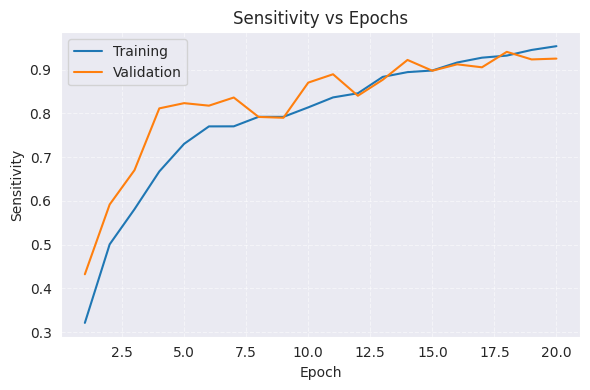

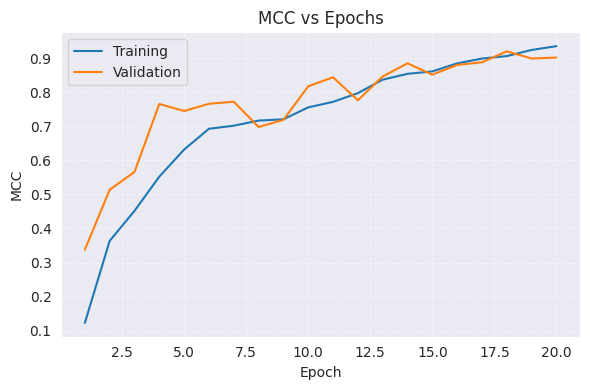

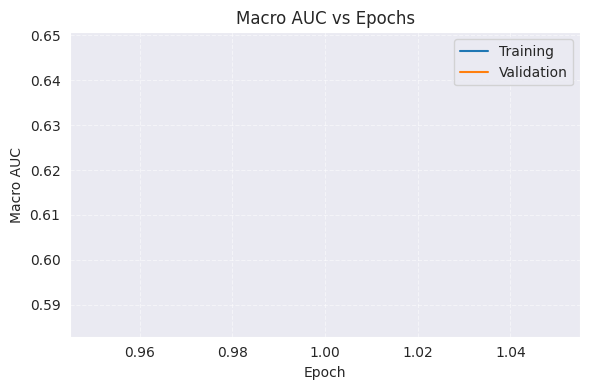

In [15]:
def plot_metric(train_values, val_values, title, ylabel):
    epochs = range(1, len(train_values) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, train_values, label="Training")
    plt.plot(epochs, val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_metric(history["loss"], history["val_loss"], "Loss vs Epochs", "Loss")
for metric, title in [
    ("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
    ("f1", "Macro F1-score"), ("specificity", "Specificity"),
    ("sensitivity", "Sensitivity"), ("mcc", "MCC"), ("auc", "Macro AUC")
]:
    plot_metric(history[metric], history[f"val_{metric}"], f"{title} vs Epochs", title)

## 14. Load best checkpoint and evaluate on the test set

In [16]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets, all_preds, all_probs = [], [], []
test_loss = 0.0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        test_loss += loss.item()
        all_targets.extend(labels.cpu().numpy())
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

all_targets = np.asarray(all_targets)
all_preds = np.asarray(all_preds)
all_probs = np.asarray(all_probs)
test_metrics = calculate_metrics(all_targets, all_preds, all_probs, num_classes)

print(f"Test loss: {test_loss / max(1, len(test_loader)):.4f}")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

Testing:   0%|          | 0/36 [00:00<?, ?it/s]

Test loss: 0.5548
accuracy: 0.9042
precision: 0.8958
recall: 0.9002
f1: 0.8967
mcc: 0.8705
auc: nan
specificity: 0.9679
sensitivity: 0.9002


## 15. Classification report and confusion matrix

                  precision    recall  f1-score   support

    glioma_tumor     0.9686    0.9333    0.9506       165
meningioma_tumor     0.8933    0.8121    0.8508       165
        no_tumor     0.8313    0.8734    0.8519        79
 pituitary_tumor     0.8901    0.9818    0.9337       165

        accuracy                         0.9042       574
       macro avg     0.8958    0.9002    0.8967       574
    weighted avg     0.9055    0.9042    0.9035       574



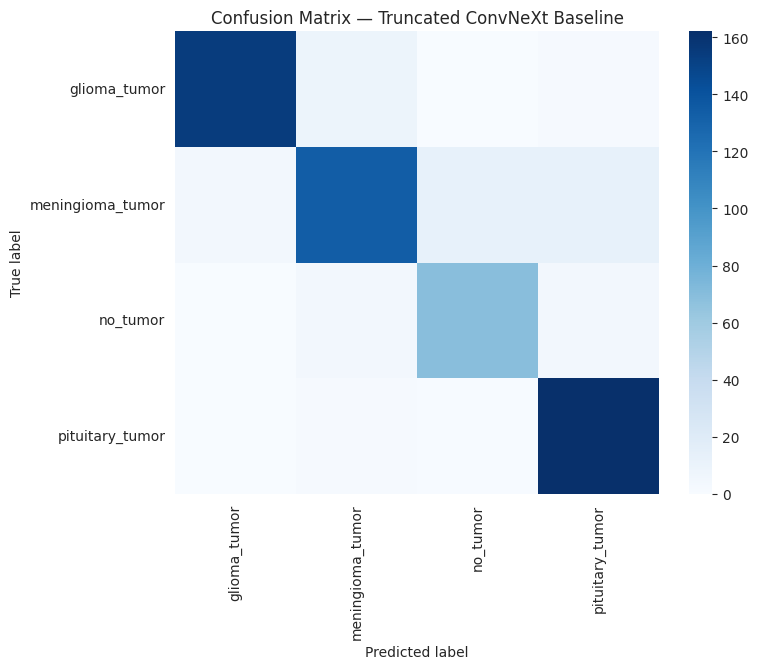

In [17]:
class_names = [idx_to_class[i] for i in range(num_classes)]
print(classification_report(
    all_targets, all_preds, labels=list(range(num_classes)),
    target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))
fig_size = max(8, min(18, 0.45 * num_classes + 5))
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — 4-Block ConvNeXt + CBAM")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Grad-CAM visualizations

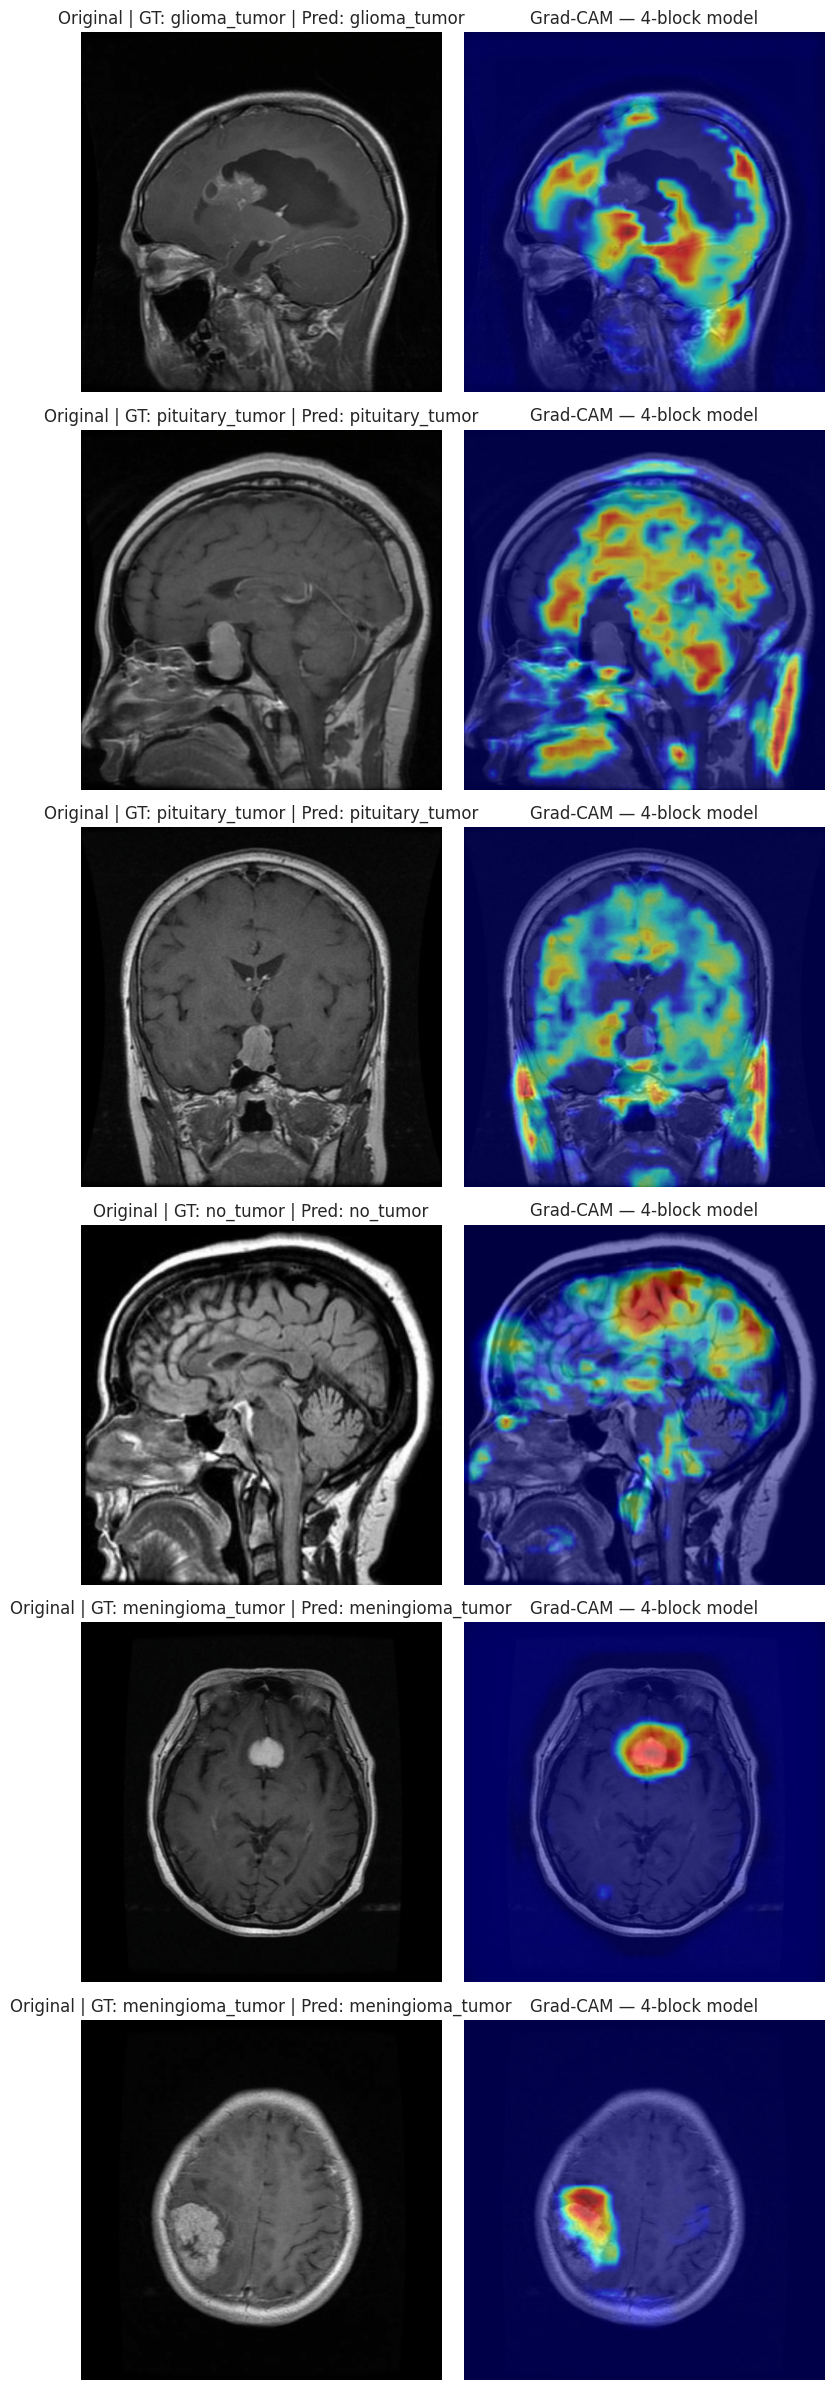

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Explain the final retained ConvNeXt block; CBAM follows the backbone feature map.
target_layers = [model.snn2.conv2]
cam = GradCAM(model=model, target_layers=target_layers)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
num_images = min(6, len(test_loader.dataset))
indices = np.random.choice(len(test_loader.dataset), num_images, replace=False)

fig, axes = plt.subplots(num_images, 2, figsize=(8, 4 * num_images))
if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

model.eval()
for i, idx in enumerate(indices):
    img, label = test_loader.dataset[idx]
    input_tensor = img.unsqueeze(0).to(device)

    with torch.no_grad():
        pred_class = model(input_tensor).argmax(dim=1).item()

    rgb = img.permute(1, 2, 0).cpu().numpy()
    rgb = np.clip(rgb * std + mean, 0, 1)
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(pred_class)]
    )[0]
    visualization = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Original | GT: {idx_to_class[int(label)]} | Pred: {idx_to_class[pred_class]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(visualization)
    axes[i, 1].set_title("Grad-CAM — ConvNeXt + CBAM + SNN + ViT")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


## 17. Save final experiment metadata

The checkpoint and metadata below identify this as the four-block truncated 28 × 28 ConvNeXt-only baseline. Keep this checkpoint separate from the full ConvNeXt-SNN model and the six-block baseline.


In [19]:
experiment_summary = {
    "experiment": "Four-block ConvNeXt-Tiny + CBAM + SNN + ViT encoder",
    "backbone": "convnext_tiny",
    "pretrained": True,
    "retained_stages": [0, 1],
    "retained_blocks_per_stage": retained_block_counts,
    "total_retained_convnext_blocks": int(sum(retained_block_counts)),
    "removed_stages": [2, 3],
    "input_shape": [3, 448, 448],
    "backbone_feature_map_shape": [192, 56, 56],
    "attention": "CBAM channel attention followed by spatial attention",
    "snn_head": "Two residual Conv-BN-LIF-Conv-BN-LIF blocks",
    "snn_beta": 0.95,
    "transformer": "Four-layer ViT-style TransformerEncoder, 6 heads, 192-dim tokens; 14x14 patch grid plus CLS token",
    "head": "CBAM + two residual SNN blocks + patch embedding + ViT encoder + CLS token + LayerNorm + Dropout(0.4) + Linear",
    "num_classes": int(num_classes),
    "class_to_idx": label_map,
    "best_validation_accuracy": float(best_val_acc),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "thop_flops": int(flops)
}

with open("convnext_4block_cbam_snn_vit_56x56_results.json", "w") as f:
    json.dump(experiment_summary, f, indent=2)

print(json.dumps(experiment_summary, indent=2))


{
  "experiment": "ConvNeXt-only truncated 4-block backbone baseline",
  "backbone": "convnext_tiny",
  "pretrained": true,
  "retained_stages": [
    0,
    1
  ],
  "retained_blocks_per_stage": [
    3,
    1
  ],
  "total_retained_convnext_blocks": 4,
  "removed_stages": [
    2,
    3
  ],
  "input_shape": [
    3,
    448,
    448
  ],
  "feature_map_shape": [
    192,
    56,
    56
  ],
  "head": "GlobalAveragePooling + LayerNorm + Dropout(0.4) + Linear",
  "num_classes": 4,
  "class_to_idx": {
    "glioma_tumor": 0,
    "meningioma_tumor": 1,
    "no_tumor": 2,
    "pituitary_tumor": 3
  },
  "best_validation_accuracy": 0.941304347826087,
  "test_metrics": {
    "accuracy": 0.9041811846689896,
    "precision": 0.8958304959418849,
    "recall": 0.9001726121979287,
    "f1": 0.89674509146171,
    "mcc": 0.8705121107147528,
    "auc": NaN,
    "specificity": 0.967868168212284,
    "sensitivity": 0.9001726121289665
  },
  "total_parameters": 624100,
  "trainable_parameters": 624100